[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/EN/chapter12_seminar_notebook.ipynb)

# Modelling Financial Markets — Seminar 12: Options and the Volatility Surface

*Seminar notebook. Daniel Traian Pele, Antoaneta Amza, Bucharest University of Economic Studies.*

- **[Solved]** problems contain the full solution; **[Proposed]** problems are solved by you.
- Part A: derivations checked on numbers (A1–A8); Part B: estimation and inference (B1–B8); Part C: open questions and AI critique.

P&L means profit and loss; OTM means out of the money.

The exercise order follows the PDF route. C1 is an AI critique; C2 and C3 are open research extensions. Some worked charts are linked to the corresponding PDF page; inline figures here cover B1 and B4.

> The solutions are discussed in the seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_12'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /Users/danpele/Documents/2026 MFM/MFM/notebooks/EN


In [2]:
import os
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats, optimize, integrate
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

N, n = stats.norm.cdf, stats.norm.pdf

## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'

HERE = '.'
SEED = 42
BASE = {'S': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2}
HEDGE = {'S0': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2, 'mu': 0.08, 'nstep': 252, 'npath': 20000}


def save_fig(name):
    """Save the figure as PDF and transparent PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles, ncol=3, y=0.0):
    """One legend for a multi-panel figure, below the figure."""
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def nw_mean(x, lags):
    """Mean and Newey-West (HAC) standard error of a series."""
    x = np.asarray(x, float)
    m = sm.OLS(x, np.ones_like(x)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(m.params[0]), float(m.bse[0])


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, pd.Timestamp):
        return str(o)
    return o


import tempfile
# SAVE_TO_DRIVE = True (Colab cell above): charts and tables go to OUT_DIR in Google Drive; otherwise to a temporary folder
KEEP = bool(globals().get('SAVE_TO_DRIVE', False))
HERE = globals().get('OUT_DIR', '.') if KEEP else tempfile.gettempdir()


def save_fig(name):
    """Show the figure; with SAVE_TO_DRIVE, also save it as PNG in OUT_DIR."""
    if KEEP:
        plt.savefig(os.path.join(HERE, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()

## Data

- Daily closes through 18 September 2026: S&P 500, Bitcoin and the Cboe Volatility Index (VIX); VIX3M is its three-month counterpart used in the signal extension.
- Bitcoin option chain: Deribit snapshot of 22 September 2026; Deribit Volatility Index (DVOL), with a 30-day implied-volatility horizon.
- Implied volatility is annualised percent. Use the date conventions in each exercise; a trading-day horizon differs from a calendar-day horizon.

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# course data: local copy when the notebook runs inside the repository, otherwise read online
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
SNAP_DIR = next((d for d in ('.', '../Quantlets/Ch_12', '../../Quantlets/Ch_12')
                 if os.path.exists(os.path.join(d, 'ch12_deribit_snapshot.csv'))), '.')
END = '2026-09-18'

# name -> (symbol, field, type)
SERIES = {
    'sp500': ('GSPC.INDX', 'close', 'index'),
    'spy':   ('SPY.US', 'adjusted_close', 'etf'),
    'btc':   ('BTC-USD.CC', 'close', 'crypto'),
    'vix':   ('VIX.INDX', 'close', 'vol'),
    'vix9d': ('VIX9D.INDX', 'close', 'vol'),
    'vix3m': ('VIX3M.INDX', 'close', 'vol'),
    'vvix':  ('VVIX.INDX', 'close', 'vol'),
}
DERIBIT = 'https://www.deribit.com/api/v2/public/'
SNAP_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_12/ch12_deribit_snapshot.csv'


def read_market(symbol):
    """Read the daily series of one symbol from the course data (local copy or online)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_close(name, start=None, end=END):
    """Daily price (or index level); except for crypto assets, weekdays only
    (days with an unchanged close are kept: they are real trading days)."""
    symbol, col, kind = SERIES[name]
    s = read_market(symbol)[col].loc[start:end]
    s = s[s > 0].dropna()
    if kind != 'crypto':
        s = s[s.index.dayofweek < 5]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def spy_open_close(start=None, end=END):
    """Daily SPY open and close (unadjusted prices: the same-day ratio does not depend on adjustments)."""
    d = read_market('SPY.US').loc[start:end, ['open', 'close']]
    d = d[(d > 0).all(axis=1)]
    return d[d.index.dayofweek < 5]


def _get(method, **params):
    url = DERIBIT + method + '?' + '&'.join(f'{k}={v}' for k, v in params.items())
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    return json.load(urllib.request.urlopen(req, timeout=60))['result']


def deribit_chain(path=None, refresh=False):
    """BTC option chain (mark prices, implied volatilities) at the snapshot time."""
    path = path or os.path.join(SNAP_DIR, 'ch12_deribit_snapshot.csv')
    if not refresh:
        for src in (path, SNAP_RAW):
            try:
                return pd.read_csv(src, parse_dates=['snapshot_utc', 'expiry'])
            except Exception:
                pass
    rows = _get('get_book_summary_by_currency', currency='BTC', kind='option')
    t0 = pd.Timestamp.now(tz='UTC').floor('min').tz_localize(None)
    out = []
    for x in rows:
        _, exp, strike, cp = x['instrument_name'].split('-')
        out.append(dict(snapshot_utc=t0, instrument=x['instrument_name'],
                        expiry=pd.to_datetime(exp, format='%d%b%y') + pd.Timedelta(hours=8),
                        strike=float(strike), type='call' if cp == 'C' else 'put',
                        mark_iv=x['mark_iv'], mark_price=x['mark_price'], bid=x['bid_price'], ask=x['ask_price'],
                        forward=x['underlying_price'], index=x['estimated_delivery_price'],
                        open_interest=x['open_interest'], volume_usd=x['volume_usd']))
    d = pd.DataFrame(out).sort_values(['expiry', 'strike', 'type']).reset_index(drop=True)
    d.to_csv(path, index=False)
    return d


def dvol_history(start='2021-03-24', end=END):
    """DVOL index (30-day implied volatility of BTC options, annualised, in %), daily values."""
    t1 = int(pd.Timestamp(end).tz_localize('UTC').timestamp() * 1000) + 86_400_000
    t0 = int(pd.Timestamp(start).tz_localize('UTC').timestamp() * 1000)
    data = []
    while True:
        r = _get('get_volatility_index_data', currency='BTC', start_timestamp=t0, end_timestamp=t1, resolution='1D')
        data += r['data']
        if not r.get('continuation') or r['continuation'] <= t0:
            break
        t1 = r['continuation']
    d = pd.DataFrame(data, columns=['t', 'open', 'high', 'low', 'close']).drop_duplicates('t')
    d.index = pd.to_datetime(d['t'], unit='ms').dt.normalize()
    return d.sort_index()['close'].loc[start:end].rename('dvol')

[Check the input snapshot](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=5): The published snapshot has 9,245 common days, 1990-01-02–2026-09-18, 986 option contracts and 11 expiries. First/last closes: S&P 500: 359.69/7650.50; VIX: 17.24/14.81. A mismatch means the input version or alignment differs; resolve it before comparing estimates.

In [5]:
_check_px = pd.concat([load_close('sp500'), load_close('vix')], axis=1, join='inner').dropna()
_check_chain = deribit_chain()
print('Common days:', len(_check_px), 'range:', _check_px.index[0].date(), _check_px.index[-1].date())
print('First/last closes:', _check_px.iloc[[0, -1]].to_dict())
print('Option contracts:', len(_check_chain), 'expiries:', _check_chain['expiry'].nunique())

Common days: 9245 range: 1990-01-02 2026-09-18
First/last closes: {'sp500': {Timestamp('1990-01-02 00:00:00'): 359.69, Timestamp('2026-09-18 00:00:00'): 7650.5}, 'vix': {Timestamp('1990-01-02 00:00:00'): 17.24, Timestamp('2026-09-18 00:00:00'): 14.81}}
Option contracts: 986 expiries: 11


## Option pricing tools

- `bs_price`, `bs_greeks`: Black–Scholes and the Greeks; `implied_vol`, `newton_iv`: implied volatility.
- `merton_price`, `heston_price`: jump and stochastic-volatility models.
- `svi_w`, `svi_fit`: Stochastic Volatility Inspired (SVI) smile; `delta_hedge`: discrete delta hedging.

In [6]:
def bs_price(S, K, T, r, sigma, kind='call', q=0.0):
    """Black-Scholes price of a European option."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == 'call':
        return S * np.exp(-q * T) * N(d1) - K * np.exp(-r * T) * N(d2)
    return K * np.exp(-r * T) * N(-d2) - S * np.exp(-q * T) * N(-d1)


def bs_greeks(S, K, T, r, sigma, kind='call', q=0.0):
    """Delta, gamma, vega (per volatility point), theta (per calendar day), rho; plus d1, d2."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    gamma = np.exp(-q * T) * n(d1) / (S * sigma * np.sqrt(T))
    vega = S * np.exp(-q * T) * n(d1) * np.sqrt(T) / 100
    common = -S * np.exp(-q * T) * n(d1) * sigma / (2 * np.sqrt(T))
    if kind == 'call':
        delta = np.exp(-q * T) * N(d1)
        theta = common - r * K * np.exp(-r * T) * N(d2) + q * S * np.exp(-q * T) * N(d1)
        rho = K * T * np.exp(-r * T) * N(d2) / 100
    else:
        delta = -np.exp(-q * T) * N(-d1)
        theta = common + r * K * np.exp(-r * T) * N(-d2) - q * S * np.exp(-q * T) * N(-d1)
        rho = -K * T * np.exp(-r * T) * N(-d2) / 100
    return dict(d1=d1, d2=d2, delta=delta, gamma=gamma, vega=vega, theta=theta / 365, rho=rho)


def implied_vol(price, S, K, T, r, kind='call', q=0.0, lo=1e-4, hi=5.0):
    """Implied volatility: the unique solution of BS(sigma) = price (vega > 0)."""
    f = lambda s: bs_price(S, K, T, r, s, kind, q) - price
    if f(lo) > 0 or f(hi) < 0:
        return np.nan
    return optimize.brentq(f, lo, hi, xtol=1e-10)


def newton_iv(price, S, K, T, r, sigma0=0.2, kind='call', steps=4):
    """Newton steps: sigma_{k+1} = sigma_k - (BS(sigma_k) - price) / vega(sigma_k)."""
    out, s = [], sigma0
    for _ in range(steps):
        p = float(bs_price(S, K, T, r, s, kind))
        v = float(bs_greeks(S, K, T, r, s, kind)['vega']) * 100
        s_new = s - (p - price) / v
        out.append(dict(sigma=s, price=p, vega=v, sigma_next=s_new))
        s = s_new
    return out


def merton_price(S, K, T, r, sigma, lam, mu_j, sig_j, kind='call', nmax=60):
    """Merton (1976): log-normal jumps ln(1+J) ~ N(mu_j, sig_j^2), intensity lam; Poisson series of BS prices."""
    kappa = np.exp(mu_j + 0.5 * sig_j ** 2) - 1
    lam2 = lam * (1 + kappa)
    tot = 0.0
    for k in range(nmax):
        s_k = np.sqrt(sigma ** 2 + k * sig_j ** 2 / T)
        r_k = r - lam * kappa + k * np.log(1 + kappa) / T
        w = stats.poisson.pmf(k, lam2 * T)
        tot = tot + w * bs_price(S, K, T, r_k, s_k, kind)
    return tot


def heston_price(S, K, T, r, v0, kappa, theta, xi, rho, kind='call'):
    """Heston (1993): call price by the Lewis (2001) formula, with the characteristic function of ln(S_T/F) (stable form)."""
    def phi(u):
        d = np.sqrt((rho * xi * 1j * u - kappa) ** 2 + xi ** 2 * (1j * u + u ** 2))
        g = (kappa - rho * xi * 1j * u - d) / (kappa - rho * xi * 1j * u + d)
        e = np.exp(-d * T)
        C = kappa * theta / xi ** 2 * ((kappa - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
        D = (kappa - rho * xi * 1j * u - d) / xi ** 2 * (1 - e) / (1 - g * e)
        return np.exp(C + D * v0)
    x = np.log(S / K) + r * T
    f = lambda u: (np.exp(1j * u * x) * phi(u - 0.5j)).real / (u ** 2 + 0.25)
    # integral over [0, 2^14] in dyadic pieces: a cut at u = 200 leaves an error of about 1e-5 in the price, which
    # visibly moves deep out-of-the-money implied volatilities
    edges = np.r_[0.0, 2.0 ** np.arange(15)]
    integral = sum(integrate.quad(f, a, b, limit=200, epsabs=1e-14, epsrel=1e-12)[0] for a, b in zip(edges[:-1], edges[1:]))
    call = S - np.sqrt(S * K) * np.exp(-r * T / 2) / np.pi * integral
    return call if kind == 'call' else call - S + K * np.exp(-r * T)


def svi_w(k, a, b, rho, m, s):
    """SVI (Gatheral): total implied variance w(k) = a + b (rho (k - m) + sqrt((k - m)^2 + s^2)), k = ln(K/F)."""
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + s ** 2))


def svi_fit(k, w, weights=None, *, return_diagnostics=False):
    """Fit the original weighted total-variance SSE within the original SVI box.

    Six starts and an analytic Jacobian resolve the local numerical fit. Boundary
    solutions remain box-dependent; convergence is not proof of a global optimum.
    Optional diagnostics expose all attempts without changing the default result.
    """
    import hashlib
    import scipy
    svi_fit.last_diagnostics = None
    k, w = np.asarray(k, dtype=float), np.asarray(w, dtype=float)
    wt = np.ones_like(w) if weights is None else np.asarray(weights, dtype=float)
    if (k.ndim != 1 or k.size == 0 or w.shape != k.shape or wt.shape != k.shape
            or not np.all(np.isfinite(k)) or not np.all(np.isfinite(w))
            or not np.all(np.isfinite(wt)) or np.any(wt < 0) or not np.isfinite(wt.sum()) or wt.sum() <= 0):
        raise ValueError('SVI requires finite equal-length vectors and nonnegative weights with positive sum.')
    bounds = np.array([(-1, 5), (1e-6, 10), (-0.999, 0.999), (-2, 2), (1e-4, 3)]).T
    root_wt = np.sqrt(wt)
    def residual(p):
        return root_wt * (svi_w(k, *p) - w)
    def jacobian(p):
        a, b, rho, m, s = p
        u = k - m
        d = np.sqrt(u * u + s * s)
        return root_wt[:, None] * np.column_stack((np.ones_like(k), rho*u+d,
                    b*u, b*(-rho-u/d), b*s/d))
    def fingerprint(values):
        return hashlib.sha256(np.ascontiguousarray(values, dtype='<f8').tobytes()).hexdigest()
    diagnostics = dict(input_sha256={name: fingerprint(value) for name, value in
                       [('k', k), ('w', w), ('weights', wt)]},
                       numpy=np.__version__, scipy=scipy.__version__, bounds=bounds.tolist(),
                       method='trf', loss='linear', x_scale='jac', ftol=None,
                       xtol=1e-14, gtol=1e-14, max_nfev=20000, attempts=[])
    svi_fit.last_diagnostics = diagnostics
    candidates = []
    for rho0 in (-0.5, 0.0, 0.3):
        for s0 in (0.05, 0.2):
            x0 = [max(w.min() * 0.5, 1e-4), 0.1, rho0, 0.0, s0]
            row = dict(start=len(diagnostics['attempts']), x0=list(x0), valid=False)
            try:
                res = optimize.least_squares(residual, x0, jac=jacobian, bounds=bounds,
                    method='trf', loss='linear', x_scale='jac', ftol=None,
                    xtol=1e-14, gtol=1e-14, max_nfev=20000)
                p = np.asarray(res.x)
                r, J = residual(p), jacobian(p)
                sse = float(r @ r)
                grad = 2 * J.T @ r
                pg = grad.copy()
                pg[(p <= bounds[0] + 1e-10) & (grad > 0)] = 0
                pg[(p >= bounds[1] - 1e-10) & (grad < 0)] = 0
                denom = 2 * np.linalg.norm(J, 2) * np.linalg.norm(r)
                scaled_pg = float(np.max(np.abs(pg)) / max(denom, np.finfo(float).tiny))
                if np.linalg.norm(r) == 0:
                    scaled_pg = 0.0
                valid = bool(res.success and res.status > 0 and np.all(np.isfinite(p))
                    and np.isfinite(sse) and np.all(p >= bounds[0]) and np.all(p <= bounds[1])
                    and np.isclose(sse, 2*res.cost, rtol=1e-10, atol=1e-24)
                    and np.isfinite(scaled_pg)
                    and (float(np.max(np.abs(pg))) <= 1e-10 or scaled_pg <= 1e-6))
                singular = np.linalg.svd(J, compute_uv=False)
                row.update(x=p.tolist(), success=bool(res.success), status=int(res.status),
                    message=str(res.message), nfev=int(res.nfev), sse=sse,
                    projected_gradient_inf=float(np.max(np.abs(pg))),
                    scaled_projected_gradient=scaled_pg, optimality=float(res.optimality),
                    active_bounds=np.flatnonzero((p <= bounds[0]+1e-10) | (p >= bounds[1]-1e-10)).tolist(),
                    singular_values=singular.tolist(), valid=valid)
                if valid:
                    candidates.append((sse, row['start'], p.copy()))
            except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:
                row['error'] = type(exc).__name__ + ': ' + str(exc)
            diagnostics['attempts'].append(row)
    if not candidates:
        raise RuntimeError('SVI: no finite, converged, stationary candidate within the original box; inspect svi_fit.last_diagnostics.')
    sse, selected, p = min(candidates, key=lambda item: item[0])
    a, b, rho, m, s = p
    result = dict(a=a, b=b, rho=rho, m=m, s=s, rmse=np.sqrt(sse / wt.sum()),
                  wmin=a + b*s*np.sqrt(1-rho**2))
    diagnostics.update(selected_start=selected, sse=sse,
                       boundary_solution=bool(diagnostics['attempts'][selected]['active_bounds']),
                       interpretation='Local minimum in the original parameter box; no global-optimum or box-insensitivity claim.')
    return (result, diagnostics) if return_diagnostics else result


def delta_hedge(paths, K, T, r, sigma_imp, n_rebal, kind='call'):
    """Sell an option at BS(sigma_imp) and delta-hedge it n_rebal times until expiry.
    paths: price matrix (n_paths, n_steps+1) on a uniform grid; n_steps divisible by n_rebal.
    Returns the hedging error at expiry (hedge portfolio value minus the option pay-off)."""
    npath, nstep = paths.shape[0], paths.shape[1] - 1
    every = nstep // n_rebal
    dt = T / nstep
    S0 = paths[:, 0]
    V0 = bs_price(S0, K, T, r, sigma_imp, kind)
    delta = bs_greeks(S0, K, T, r, sigma_imp, kind)['delta']
    cash = V0 - delta * S0
    for i in range(1, nstep + 1):
        cash = cash * np.exp(r * dt)
        if i % every == 0 and i < nstep:
            tau = T - i * dt
            d_new = bs_greeks(paths[:, i], K, tau, r, sigma_imp, kind)['delta']
            cash -= (d_new - delta) * paths[:, i]
            delta = d_new
    ST = paths[:, -1]
    payoff = np.maximum(ST - K, 0) if kind == 'call' else np.maximum(K - ST, 0)
    return cash + delta * ST - payoff

## Seminar functions

- Simulated paths, the Bitcoin surface and the variance risk premium of the S&P 500 (the seminar's helper code).

In [7]:
B_BOOT = 1000
A8_K = [80, 85, 90, 95, 100, 105, 110, 115, 120]
BFLY_EXPIRY = '2026-10-30 08:00:00'


def gbm_paths(S0, mu, sigma, T, nstep, npath, seed=SEED):
    rng = np.random.default_rng(seed)
    dt = T / nstep
    z = rng.standard_normal((npath, nstep))
    x = np.cumsum((mu - 0.5 * sigma ** 2) * dt + sigma * np.sqrt(dt) * z, axis=1)
    return S0 * np.exp(np.hstack([np.zeros((npath, 1)), x]))


def btc_surface():
    """SVI fit for every expiry of the BTC chain (quoted OTM options, at least 2 days to expiry)."""
    c = deribit_chain()
    t0 = c['snapshot_utc'].iloc[0]
    c['T'] = (c['expiry'] - t0).dt.total_seconds() / (365 * 86400)
    c = c[(c['T'] >= 2 / 365) & (c['mark_iv'] > 0) & (c['bid'] > 0)]
    c = c[((c['type'] == 'put') & (c['strike'] < c['forward'])) | ((c['type'] == 'call') & (c['strike'] >= c['forward']))].copy()
    c['k'] = np.log(c['strike'] / c['forward'])
    c['w'] = (c['mark_iv'] / 100) ** 2 * c['T']
    c = c[c['k'].abs() < 1.2]
    fits = {}
    for e, g in c.groupby('expiry'):
        if len(g) < 7:
            continue
        f = svi_fit(g['k'].values, g['w'].values)
        T = g['T'].iloc[0]
        iv = lambda k: 100 * np.sqrt(svi_w(k, f['a'], f['b'], f['rho'], f['m'], f['s']) / T)
        fits[e] = dict(T=T, days=T * 365, F=float(g['forward'].iloc[0]), n=int(len(g)), atm=float(iv(0.0)),
                       rr=float(iv(0.15) - iv(-0.15)), wing_dn=float(iv(-0.3)), wing_up=float(iv(0.3)),
                       rmse_iv=float(np.sqrt(np.mean((iv(g['k'].values) - g['mark_iv'].values) ** 2))), **f)
    tab = pd.DataFrame(fits).T
    tab.index.name = 'expiry'
    tab.to_csv(os.path.join(HERE, 'ch12_btc_svi.csv'))
    return c, tab, t0


def pick(tab, days):
    """Expiry closest to a given number of days."""
    return (tab['days'] - days).abs().astype(float).idxmin()


def vrp_sp500():
    """Variance risk premium: VIX^2 minus realised variance over the next 21 trading days."""
    px = pd.concat([load_close('sp500'), load_close('vix')], axis=1, join='inner').dropna()
    r = np.log(px['sp500']).diff()
    rv = 252 / 21 * (r ** 2).rolling(21).sum().shift(-21) * 1e4       # annualised (%)^2
    d = pd.DataFrame({'vix': px['vix'], 'iv2': px['vix'] ** 2, 'rv': rv, 'rv_past': rv.shift(21)}).dropna()
    d['vrp'] = d['iv2'] - d['rv']
    d['vrp_vol'] = d['vix'] - np.sqrt(d['rv'])
    return d


def qlike(rv, f):
    return rv / f - np.log(rv / f) - 1


def hac_se(u, lags):
    """HAC (Newey-West, Bartlett) standard error of the mean of a series."""
    u = np.asarray(u, float)
    return nw_mean(u, lags)[1]

## Pricing, hedging and forecast evaluation

### A1. One identity for all the Greeks [Solved]

- **Questions**

  - why are the gamma and the vega of options with the same expiry proportional?

  - what are they for an at-the-money call?

- **Inputs**

  - The Black–Scholes call in [“Geometric Brownian Motion and the Black–Scholes Price”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p4); no dividends

  - Numbers: $S = K = 100$, six months ($\tau = 0.5$), $r = 3\%$, $\sigma = 25\%$; no data file

- **Tasks**

  1.  Prove the identity $S\varphi(d_1) = K e^{-r\tau}\varphi(d_2)$ by computing $d_1^2 - d_2^2$.

  2.  Use the identity to show that $\Delta = \Phi(d_1)$ and vega $= S\varphi(d_1)\sqrt{\tau}$.

  3.  Show that vega $= \Gamma S^2\sigma\tau$, with $\Gamma$ in [“The Greeks”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p5).

  4.  Compute $d_1$, $d_2$, both sides of the identity, $\Delta$, $\Gamma$, vega in two ways, the call, and the put from put–call parity.

- **Report**: the three proofs, a table of the numbers, and one sentence on what vega $= \Gamma S^2\sigma\tau$ implies for hedging gamma with options of the same expiry

- Notebook: section [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)

- Step 1: $\varphi(d_2)/\varphi(d_1) = e^{(d_1^2 - d_2^2)/2}$ and $d_1^2 - d_2^2 = (d_1 - d_2)(d_1 + d_2) = \sigma\sqrt{\tau} \cdot \dfrac{2\ln(S/K) + 2r\tau}{\sigma\sqrt{\tau}}$

- Hence $\varphi(d_2)/\varphi(d_1) = S e^{r\tau}/K$, i.e. $S\varphi(d_1) = K e^{-r\tau}\varphi(d_2)$

- Step 2: $\partial_S C = \Phi(d_1) + [S\varphi(d_1) - K e^{-r\tau}\varphi(d_2)]\,\partial_S d_1 = \Phi(d_1)$, since $\partial_S d_1 = \partial_S d_2$ and the bracket is 0 by Step 1

- Vega: $S\varphi(d_1)\partial_\sigma d_1 - K e^{-r\tau}\varphi(d_2)\partial_\sigma d_2 = S\varphi(d_1)\,\partial_\sigma(d_1 - d_2) = S\varphi(d_1)\sqrt{\tau}$

- Step 3: $\Gamma S^2\sigma\tau = \dfrac{\varphi(d_1)}{S\sigma\sqrt{\tau}}\, S^2\sigma\tau = S\varphi(d_1)\sqrt{\tau}$ = vega



- Step 4: $\sigma\sqrt{\tau} = 0.1768$, $d_1 = (0.03 + 0.03125) \cdot 0.5/0.1768 = 0.1732$, $d_2 = -0.0035$; identity: $100 \cdot 0.3930 = 39.30$ and $98.51 \cdot 0.3989 = 39.30$

- $\Delta = 0.5688$, $\Gamma = 0.0222$; vega $= 100 \cdot 0.3930\sqrt{0.5} = 27.79 = \Gamma S^2\sigma\tau = 27.79$ per unit of $\sigma$ ($0.2779$ per vol point); $C = 7.76$, $P = C - 100 + 98.51 = 6.27$

- **Interpretation**: for one expiry vega and gamma are proportional, so a gamma-neutral book of same-expiry options is also vega-neutral, but only while the smile is flat (extension [A7](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A7))

[Exercise A1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)

[Worked chart](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=22)

a5_bs is the legacy function name for the A1 Black–Scholes inputs; it is defined here and reused by A5. d1/d2 and Nd1/Nd2 are arguments and Normal probabilities; gamma and vega use the stated price/volatility units.

In [8]:
def a5_bs():
    """Black-Scholes step by step: S = K = 100, T = 6 months, r = 3%, sigma = 25%."""
    S, K, T, r, s = 100.0, 100.0, 0.5, 0.03, 0.25
    g = bs_greeks(S, K, T, r, s)
    return dict(d1=float(g['d1']), d2=float(g['d2']), Nd1=float(stats.norm.cdf(g['d1'])), Nd2=float(stats.norm.cdf(g['d2'])),
                pvk=K * np.exp(-r * T), C=float(bs_price(S, K, T, r, s)), P=float(bs_price(S, K, T, r, s, 'put')),
                delta=float(g['delta']), gamma=float(g['gamma']), vega=float(g['vega']), theta=float(g['theta']),
                nd1=float(stats.norm.pdf(g['d1'])))


# Solution
g5 = a5_bs()
print(100 * g5['nd1'], g5['pvk'] * stats.norm.pdf(g5['d2']))
print(100 * g5['nd1'] * np.sqrt(0.5), g5['gamma'] * 100 ** 2 * 0.25 * 0.5)

39.30003473760774 39.30003473760773
27.789321063829313 27.789321063829313


### A2. Implied volatility: existence, uniqueness, starting value [Solved]

- **Questions**

  - which volatility makes the Black–Scholes price equal to a market price of 4.50?

  - Before calculating, write whether a price above the model price requires a higher or lower volatility, and explain your prediction using vega. Then check it with Newton.

- **Inputs**: a European call with $S = K = 100$, three months ($\tau = 0.25$), $r = 2\%$, market price 4.50; vega $\mathcal{V}(\sigma) = S\varphi(d_1)\sqrt{\tau}$ from [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)

- **Tasks**

  1.  Prove that $\sigma \mapsto BS(\sigma)$ is continuous and strictly increasing, with limits $(S - Ke^{-r\tau})^+$ as $\sigma \to 0$ and $S$ as $\sigma \to \infty$, and state when an implied volatility exists.

  2.  Derive the at-the-money-forward approximation $C \approx S\sigma\sqrt{\tau}/\sqrt{2\pi}$ [Brenner & Subrahmanyam (1988)](https://doi.org/10.2469/faj.v44.n5.80).

  3.  Invert it to get two starting values: from the price 4.50, and from 4.50 minus half the discounted forward intrinsic value $(S - Ke^{-r\tau})/2$.

  4.  Run one Newton step $\sigma_1 = \sigma_0 - (BS(\sigma_0) - 4.50)/\mathcal{V}(\sigma_0)$ from $\sigma_0 = 20\%$ and compare $\sigma_1$ with the exact implied volatility.

- **Report**: the two starting values, $\sigma_1$ and the exact implied volatility; one sentence on why Newton converges so fast here and when it would fail

- Notebook: section [A2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A2)

- Step 1: $\partial_\sigma BS = S\varphi(d_1)\sqrt{\tau} > 0$ ([A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)): strictly increasing and continuous

- $\sigma \to 0$: $d_{1,2} \to \pm\infty$ according to the sign of $\ln(S/K) + r\tau$, so $BS \to (S - Ke^{-r\tau})^+$; $\sigma \to \infty$: $d_1 \to \infty$, $d_2 \to -\infty$, so $BS \to S$

- By the intermediate value theorem a unique $\sigma_{imp}$ exists if and only if the price lies strictly inside the no-arbitrage bounds $(S - Ke^{-r\tau})^+ < C < S$

- Step 2: if $S = Ke^{-r\tau}$, $d_{1,2} = \pm\sigma\sqrt{\tau}/2$ and $C = S[\Phi(\sigma\sqrt{\tau}/2) - \Phi(-\sigma\sqrt{\tau}/2)] \approx S\,\sigma\sqrt{\tau}\,\varphi(0) = S\sigma\sqrt{\tau}/\sqrt{2\pi}$

- Step 3: without correction $\sigma \approx 4.50\sqrt{2\pi}/(100 \cdot 0.5) = 22.56\%$

- With correction: $Ke^{-r\tau} = 99.501$, half the forward intrinsic value $0.249$, $\sigma \approx (4.50 - 0.249)\sqrt{2\pi}/50 = 21.31\%$

- Step 4: $BS(20\%) = 4.2322$, $\mathcal{V} = 19.848$, so $\sigma_1 = 0.20 - (4.2322 - 4.50)/19.848 = 21.3495\%$; exact $21.3495\%$

- **Interpretation**: near the money the price is almost linear in $\sigma$, so one step gives four decimals; deep out of the money vega $\approx 0$ and Newton can overshoot: use a bracketing solver (Brent)

[Exercise A2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A2)

[Worked chart](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=25)

a7_newton is the legacy name for the A2 calculation. steps lists Newton iterates; exact is the numerical root used to check convergence.

In [9]:
# Solution
def a7_newton():
    """Implied volatility by Newton: call S = K = 100, T = 3 months, r = 2%, market price 4.50, sigma_0 = 20%."""
    steps = newton_iv(4.50, 100.0, 100.0, 0.25, 0.02, sigma0=0.20, steps=3)
    return dict(steps=steps, exact=implied_vol(4.50, 100.0, 100.0, 0.25, 0.02))


pvk = 100 * np.exp(-0.02 * 0.25)
print(4.50 * np.sqrt(2 * np.pi) / 50, (4.50 - (100 - pvk) / 2) * np.sqrt(2 * np.pi) / 50)
r = a7_newton()
print(pd.DataFrame(r['steps']).round(6))
r['exact']

0.22559654471679003 0.21309468404085724
      sigma     price       vega  sigma_next
0  0.200000  4.232160  19.847627    0.213495
1  0.213495  4.499998  19.847204    0.213495
2  0.213495  4.500000  19.847204    0.213495


0.21349492122828795

### B1. Hedging error and rebalancing frequency [Solved]

- **Question**: how fast does the hedging error of a delta-hedged call shrink as the dealer rebalances more often?

- **Inputs**

  - Simulated data: 10 000 paths of geometric Brownian motion, $S_0 = 100$, $\mu = 8\%$, $\sigma = 20\%$, 252 steps over three months (seed 42)

  - A three-month At the Money (ATM) call ($K = 100$, $r = 4\%$) sold at its Black–Scholes premium $4.49$ and delta-hedged at $\sigma = 20\%$

- **Tasks**

  1.  For each $N \in \{6, 12, 21, 63, 126, 252\}$, rebalance the hedge $N$ times and compute on every path the hedging error at expiry: shares plus cash minus the pay-off.

  2.  Compute the standard deviation of the error for each $N$ and a 95% confidence interval (CI) by percentile bootstrap from 1 000 resamples of the paths [Efron (1979)](https://doi.org/10.1214/aos/1176344552).

  3.  Regress $\ln$(s.d.) on $\ln N$ and give the slope with a bootstrap interval from the same resamples.

  4.  Find the smallest $N$ in the list for which the standard deviation is below 10% of the premium.

- **Report**: a table of standard deviations with intervals, the log-log chart and the slope; one sentence on whether the slope is consistent with $-1/2$ and what transaction costs would change

- Notebook: section [B1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B1)

- Step 1: on each path, sell the call at $4.49$, buy $\Delta_0$ shares, finance with cash at $r$; at each rebalancing date reset $\Delta$; at expiry, error = shares + cash $-$ pay-off

- Step 2: the s.d. falls from $1.356$ ($N = 6$) to $0.219$ ($N = 252$); the intervals are narrow because 10 000 paths give a precise s.d.

<div class="center">

| $N$ | 6 | 12 | 21 | 63 | 126 | 252 |
|:---|---:|---:|---:|---:|---:|---:|
| s.d. | $1.356$ | $0.963$ | $0.744$ | $0.430$ | $0.306$ | $0.219$ |
| 95% CI | $[1.331, 1.381]$ | $[0.945, 0.983]$ | $[0.731, 0.758]$ | $[0.422, 0.438]$ | $[0.300, 0.312]$ | $[0.215, 0.223]$ |

</div>

- Step 3: slope $-0.489$, 95% CI $[-0.496, -0.482]$: close to $-1/2$ and slightly above it at these finite $N$; the $1/\sqrt{N}$ law of the primer is asymptotic

- Step 4: daily hedging ($N = 63$) leaves $9.6\%$ of the premium, about the 10% target; four times a day halves it again (ratio $1.97$)

- **Interpretation**: with a fixed fee per trade, costs grow like $N$ while the error falls like $1/\sqrt{N}$; the best frequency depends on the cost model and on the trade-off chosen between risk and cost

[Exercise B1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B1)

ratio_63_252 compares hedging-error standard deviations at 63 and 252 rebalances; it is not a ratio of mean P&Ls.

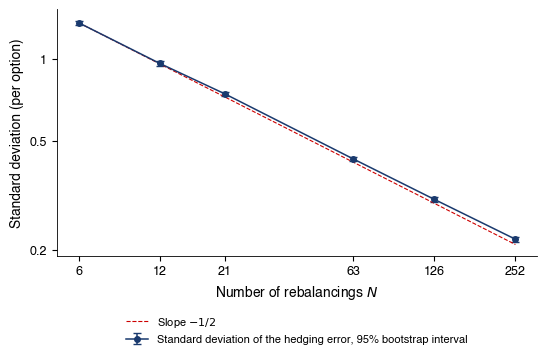

{'prem': 4.485236409022086,
 'sd': {6: 1.3561114441807223,
  12: 0.9630296813486001,
  21: 0.7441251928683007,
  63: 0.4301379906209573,
  126: 0.3059805862658455,
  252: 0.21876310249452238},
 'ci': {6: (1.3312248262461828, 1.3814845678931342),
  12: (0.9453436758236601, 0.9828037011914749),
  21: (0.7307205864922295, 0.7582203370962783),
  63: (0.4216674626228608, 0.4380982311607113),
  126: (0.3003316101381488, 0.3115477077930295),
  252: (0.2145679028364728, 0.22296632255053228)},
 'slope': -0.4886660065637433,
 'slope_lo': -0.49578489854734725,
 'slope_hi': -0.48233299994935763,
 'ratio_63_252': 1.966227328631562}

In [10]:
# Solution
def b1_hedge_boot():
    """Hedging error (standard deviation) for N rebalancings, with a 95% bootstrap interval; log-log slope."""
    rng = np.random.default_rng(SEED)
    S0, K, T, r, s, mu = 100.0, 100.0, 0.25, 0.04, 0.20, 0.08
    paths = gbm_paths(S0, mu, s, T, 252, 10000, seed=SEED)
    prem = float(bs_price(S0, K, T, r, s))
    Ns = [6, 12, 21, 63, 126, 252]
    E = {n: delta_hedge(paths, K, T, r, s, n) for n in Ns}
    idx = rng.integers(0, paths.shape[0], size=(B_BOOT, paths.shape[0]))
    sd = {n: float(E[n].std()) for n in Ns}
    boot = {n: np.array([E[n][i].std() for i in idx]) for n in Ns}
    ci = {n: (float(np.quantile(boot[n], 0.025)), float(np.quantile(boot[n], 0.975))) for n in Ns}
    x = np.log(Ns)
    slope = float(np.polyfit(x, np.log([sd[n] for n in Ns]), 1)[0])
    bs_slopes = np.array([np.polyfit(x, np.log([boot[n][b] for n in Ns]), 1)[0] for b in range(B_BOOT)])
    fig, ax = plt.subplots(figsize=(6.2, 3.2))
    y = np.array([sd[n] for n in Ns]); lo = np.array([ci[n][0] for n in Ns]); hi = np.array([ci[n][1] for n in Ns])
    ax.errorbar(Ns, y, yerr=[y - lo, hi - y], fmt='o-', color=MainBlue, ms=4, capsize=3,
                label='Standard deviation of the hedging error, 95% bootstrap interval')
    ax.plot(Ns, y[0] * np.sqrt(Ns[0] / np.array(Ns)), color=IDAred, lw=0.8, ls='--', label='Slope $-1/2$')
    ax.set_xscale('log'); ax.set_yscale('log')
    from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
    ax.xaxis.set_major_locator(FixedLocator(Ns)); ax.xaxis.set_major_formatter(FixedFormatter([str(n) for n in Ns]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_locator(FixedLocator([0.2, 0.5, 1])); ax.yaxis.set_major_formatter(FixedFormatter(['0.2', '0.5', '1']))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_xlabel('Number of rebalancings $N$'); ax.set_ylabel('Standard deviation (per option)')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig('ch12_sem_hedge')
    return dict(prem=prem, sd=sd, ci=ci, slope=slope, slope_lo=float(np.quantile(bs_slopes, 0.025)),
                slope_hi=float(np.quantile(bs_slopes, 0.975)), ratio_63_252=sd[63] / sd[252])


b1_hedge_boot()

### B2. The variance risk premium of the S&P 500 [Solved]

- **Questions**

  - is the variance risk premium of the S&P 500 significantly positive?

  - was it the same before and after 2008?

- **Inputs**

  - Daily S&P 500 and VIX closes joined on common days, January 1990 – August 2026 (the last 21-day window ends in September 2026)

  - $RV_{t, t + 21}$ ([Notation (2/2)](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12n2), $A = 252$, $h = 21$) and $VRP_t$ in %$^2$ and in vol points, as in [“The Variance Risk Premium”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p14)

- **Tasks**

  1.  Build $RV_{t, t + 21}$ from the next 21 log returns and $VRP_t$. Retain the common sample with complete future and past 21-return windows, including $RV_{t-21,t}$ used by the forecast comparison.

  2.  Compute the mean Variance Risk Premium (VRP), its Newey–West standard error with 21 lags [Newey & West (1987)](https://doi.org/10.2307/1913610), a 95% interval, and the naive standard error $s/\sqrt{n}$.

  3.  Repeat step 2 in vol points and compute the share of days with a positive premium.

  4.  Repeat for 1990–2007 and 2008–2026, then test equality by regressing $VRP_t$ on a constant and a 2008–2026 dummy with Newey–West errors (21 lags).

- **Report**: a table by period and the chart; one sentence each

  - why is the naive standard error wrong here?

  - by how much is it wrong?

  - is the premium stable?

  - why is the variance premium less precise than the vol-point premium?

- Notebook: section [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2)

<div class="center">

|  | $n$ | Mean VRP (%$^2$) | 95% CI | Vol points (s.e.) | Positive |
|:---|---:|---:|---:|---:|---:|
| 1990–2026 | 9 203 | $113.1$ | $[72.7, 153.6]$ | $4.09$ ($0.27$) | $86\%$ |
| 1990–2007 | 4 516 | $149.3$ | $[125.2, 173.5]$ | $4.60$ ($0.25$) | $88\%$ |
| 2008–2026 | 4 687 | $78.3$ | $[2.7, 153.9]$ | $3.60$ ($0.46$) | $84\%$ |

</div>

- Steps 1–2: regress $VRP_t$ on a constant with Heteroskedasticity and Autocorrelation Consistent (HAC) standard errors (Bartlett, 21 lags: the overlap); interval $=$ mean $\pm 1.96$ s.e.; full sample $t = 113.1/20.6 = 5.49$: reject $H_0$ at 5%

- Naive s.e. $5.3$ vs Newey–West $20.6$: $3.9$ times too small, because consecutive windows share 20 of 21 days

- Step 3: vol points $4.09$ (s.e. $0.27$), positive on $86\%$ of days; Step 4: 1990–2007 $t = 12.12$, 2008–2026 $t = 2.03$; difference $-71.0$ %$^2$ ($p = 0.08$), in vol points $-1.01$ ($p = 0.06$)

- **Interpretation**: squaring magnifies the crisis windows (2008, 2020), so the variance premium has heavier tails and a wider interval than the vol-point premium; the premium is positive in both subperiods, but the difference in size is not significant at 5%: the data cannot tell whether it changed

[Exercise B2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2)

[Worked chart](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=32)

b5_vrp is the legacy name for B2. all/p1/p2 refer to the full sample and the two subperiods; mean/se/lo/hi use variance units, mean_vol/se_vol use volatility points. ratio_se contrasts robust and naive uncertainty; the linked figure visualises the same sample.

In [11]:
# Solution
def b5_vrp():
    """S&P 500 variance risk premium: mean, Newey-West error (21 lags), subperiods."""
    d = vrp_sp500()
    out = {}
    for tag, x in [('all', d), ('p1', d.loc[:'2007-12-31']), ('p2', d.loc['2008-01-01':])]:
        m, se = nw_mean(x['vrp'], 21)
        mv, sev = nw_mean(x['vrp_vol'], 21)
        out[tag] = dict(n=int(len(x)), mean=m, se=se, t=m / se, lo=m - 1.96 * se, hi=m + 1.96 * se, mean_vol=mv, se_vol=sev,
                        share=float((x['vrp'] > 0).mean()), iv=float(x['vix'].mean()), rv=float(np.sqrt(x['rv']).mean()))
    # stability across subperiods: VRP on a constant and a 2008-2026 dummy, Newey-West errors (21 lags)
    X = sm.add_constant(pd.Series((d.index >= '2008-01-01').astype(float), index=d.index, name='post'))
    for col, tag in [('vrp', 'diff'), ('vrp_vol', 'diff_vol')]:
        m = sm.OLS(d[col], X).fit(cov_type='HAC', cov_kwds={'maxlags': 21})
        out[tag] = dict(d=float(m.params['post']), se=float(m.bse['post']), t=float(m.tvalues['post']),
                        p=float(m.pvalues['post']))
    naive = d['vrp'].std() / np.sqrt(len(d))
    out['naive_se'] = float(naive)
    out['ratio_se'] = out['all']['se'] / float(naive)
    return out


b5_vrp()

{'all': {'n': 9203,
  'mean': 113.1422810966194,
  'se': 20.621026303086406,
  't': 5.486743454649737,
  'lo': 72.72506954257005,
  'hi': 153.55949265066874,
  'mean_vol': 4.0914362055217435,
  'se_vol': 0.2666941672924536,
  'share': 0.858307073780289,
  'iv': 19.43508964468108,
  'rv': 15.343653439159336},
 'p1': {'n': 4516,
  'mean': 149.32446003340172,
  'se': 12.319609516855365,
  't': 12.12087605772731,
  'lo': 125.1780253803652,
  'hi': 173.47089468643824,
  'mean_vol': 4.60408609695,
  'se_vol': 0.2543637310212443,
  'share': 0.8810894596988486,
  'iv': 18.954441984056686,
  'rv': 14.350355887106689},
 'p2': {'n': 4687,
  'mean': 78.28016885456499,
  'se': 38.55935115281425,
  't': 2.0301215273134003,
  'lo': 2.7038405950490585,
  'hi': 153.85649711408092,
  'mean_vol': 3.5974897771688537,
  'se_vol': 0.4600916554436002,
  'share': 0.8363558779603157,
  'iv': 19.8982014081502,
  'rv': 16.30071163098135},
 'diff': {'d': -71.04429117884466,
  'se': 40.478686743894556,
  't': -1.7

### C1. Critique an AI answer [Proposed]

**Supplied response to audit (contains deliberate errors)**

- A student asks an Artificial Intelligence (AI) assistant: “Price a European call with 90 calendar days to expiry on a non-dividend-paying stock with $S = 100$, $K = 105$, volatility 20%, continuous rate $r = 4\%$; then give the put from put–call parity”

- The assistant answers with this code:

<!-- -->

    import numpy as np
    from scipy.stats import norm
    S, K, r, sigma = 100.0, 105.0, 0.04, 20        # sigma = 20%
    T = 90 / 252                                   # 90 days
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    put = call + S - K * np.exp(-r * T)            # put-call parity
    print(f"call = {call:.2f}, put = {put:.2f}")

- “The code follows Black–Scholes exactly; the put comes from parity, so no second formula is needed”

- **Questions**

  - which three errors does the AI answer contain?

  - which check catches each of them?

- **Inputs**: the code above; everything except three lines is correct

- **Tasks**

  1.  Before running the code, estimate what a 90-day call 5% out of the money should cost: 0.2, 2 or 20.

  2.  For each error, say what is wrong and why, and how you would detect it: a no-arbitrage bound, a unit check, today’s primer, or a second method.

  3.  Correct the three lines, run the code, report $C$ and $P$, and check put–call parity numerically.

  4.  Log the three errors in `AI_ERRORS.md` with the fields: what was asked, what the AI answered, what was wrong, how you found out, the correct version.

- **Report**: the corrected code and output; one sentence on which error still gives a plausible-looking price, and one on why “the put comes from parity” is not a check of the call

- **Model**: [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1), [A2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A2) (Black–Scholes step by step)

[Exercise C1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-C1)

In [12]:
# Your code here


### B3. Is the VIX an efficient forecast? [Proposed]

- **Question**: is $VIX_t^2$ an unbiased and efficient forecast of the variance realised over the next 21 trading days?

- **Inputs**

  - The daily series of [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2): $RV_{t, t + 21}$ and $VIX_t^2$, 1990–2026; past variance $RV_{t - 21, t}$

  - For step 4: the log Heterogeneous Autoregressive (HAR)-Realised Variance (RV), its level forecast and the Quasi-Likelihood (QLIKE) loss in [“Comparing Variance Forecasts: HAR-RV, QLIKE, Diebold–Mariano”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p17) (each average floored at 0.01 %$^2$)

- **Model**: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2) (Newey–West inference)

- Notebook: section [B3](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B3)

- **Tasks**

  1.  Estimate $RV_{t, t + 21} = \alpha + \beta\,VIX_t^2 + \varepsilon_t$ [Mincer & Zarnowitz (1969)](https://www.nber.org/books-and-chapters/economic-forecasts-and-expectations-analysis-forecasting-behavior-and-performance/evaluation-economic-forecasts) with Newey–West errors (21 lags); test $\alpha = 0$ and $\beta = 1$ separately and jointly (Wald, 5%), and report $\mathrm{corr}(\hat\alpha, \hat\beta)$.

  2.  Add $RV_{t - 21, t}$ as a second regressor; then re-estimate in logs, $\ln RV$ on $\ln VIX^2$, and test $\beta = 1$.

  3.  Instrument $\ln VIX_t^2$ with $\ln VIX_{t - 21}^2$ [Christensen & Prabhala (1998)](https://doi.org/10.1016/S0304-405X(98)00034-8) (just-identified Generalized Method of Moments (GMM), HAC covariance); report the first-stage $t$ and test $\beta = 1$.

  4.  From 2000, re-estimate every 21 days on an expanding window of observed targets; compare VIX$^2$ with HAR-RV by QLIKE loss and a Diebold–Mariano test with HAC (21 lags) [Diebold & Mariano (1995)](https://doi.org/10.1080/07350015.1995.10524599), [Patton (2011)](https://doi.org/10.1016/j.jeconom.2010.03.034).

- **Report**: all estimates and tests with decisions at 5%; one sentence each

  - why can both $t$-statistics be small while the joint test rejects?

  - what must the instrument satisfy?

  - does in-sample significance survive out of sample?

[Exercise B3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B3)

Replication benchmark: the public lecture already reports this analysis. Use the course example (slide [Is the VIX a Good Forecast?](https://danpele.github.io/MFM/EN/Courses/chapter12_options_volatility_surface.pdf#nameddest=ch12vixforecast)) to check your own implementation; copying its headline result is not the exercise. Report alignment, units and inferential conventions.

In [13]:
# Your code here


### B4. An SVI smile for Bitcoin [Solved]

- **Questions**

  - does a five-parameter SVI curve describe the Bitcoin smile?

  - how precisely are its at-the-money level and its skew estimated?

- **Inputs**

  - Option snapshot of the lecture; expiry closest to 30 days: 2026-10-30, $38$ days, 56 quoted out-of-the-money (OTM) options (puts below the forward, calls above); for each quote $k = \ln(K/F)$ and $w = \sigma_{mark}^2\tau$, with $\sigma_{mark}$ the mark Implied Volatility (IV)

  - Retain quotes with positive bid and mark IV, at least two days to expiry, and $|k|<1.2$; a fitted expiry needs at least seven quotes. Convert mark IV from percent to decimal before computing $w$.

  - the SVI curve $w(k)$ in [“The Smile and the SVI Curve”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p11) [Gatheral & Jacquier (2014)](https://doi.org/10.1080/14697688.2013.819986); the butterfly function $g(k)$ in [“Fitting a Smile and Reading a Density from It”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p12): $g \ge 0$ for all $k$ means a nonnegative density

- **Tasks**

  1.  Fit the five SVI parameters by least squares on $w$, with $b \ge 0$, $|\rho| < 1$, $s > 0$, and report the root mean squared error in vol points.

  2.  Resample the quotes with replacement 300 times, refit SVI each time, and report 95% intervals for the ATM volatility and the skew $IV(0.15) - IV(-0.15)$.

  3.  Evaluate $g(k)$ on $k \in [-1.5, 1.5]$ and report its minimum.

- **Report**: parameters, intervals, $\min g$ and the chart of quotes, fit and band; one sentence each: which parameter controls the skew and its sign; is the skew significantly different from 0; why fit $w$ and not prices

- Notebook: section [B4](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B4)

- Step 1: $\hat a = -0.0204$, $\hat b = 0.1016$, $\hat\rho = -0.2615$, $\hat m = -0.0787$, $\hat s = 0.3482$; root mean squared error $0.42$ vol points

- Step 2: ATM volatility $36.37\%$, 95% CI $[36.10, 36.87]$; skew $-2.11$, 95% CI $[-2.73, -1.52]$

- Step 3: $\min_k g(k) = 0.1359 > 0$ on $k \in [-1.5, 1.5]$: no butterfly arbitrage on this grid

- $\rho$ controls the tilt: $\hat\rho < 0$ makes the put wing dearer; the skew interval excludes 0, so the tilt is significant at 5%

- Why $w$: it is comparable across strikes and nearly linear in the wings, while option prices span four orders of magnitude and would weight the fit towards the dearest options

- A positive density everywhere also needs $g \ge 0$ outside the grid and the wing conditions of [Gatheral & Jacquier (2014)](https://doi.org/10.1080/14697688.2013.819986)

- **Interpretation**: the bootstrap resamples smoothed mark volatilities, so the intervals measure fitting noise, not bid–ask uncertainty: they are a lower bound on the true uncertainty

[Exercise B4 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B4)

b3_svi is the legacy name for B4. Read the ATM level and skew with their bootstrap intervals; a no-butterfly grid check is conditional on the fitted SVI family.

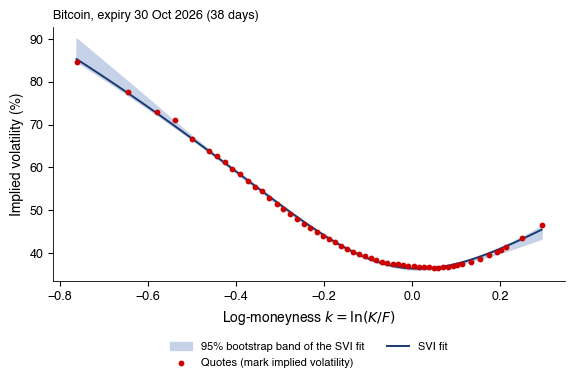

{'expiry': '2026-10-30',
 'days': 38.00625,
 'n': 56,
 'a': -0.020118416761540726,
 'b': 0.10131916183320558,
 'rho': -0.26334811344844206,
 'm': -0.07918714458390937,
 's': 0.3464220267808273,
 'rmse': 0.42441811015902614,
 'atm': 36.36941906636789,
 'rr': -2.0907794271522278,
 'atm_lo': 36.15908191132711,
 'atm_hi': 36.71543758134498,
 'rr_lo': -2.6250998686567986,
 'rr_hi': -1.6869897095541904,
 'gmin': 0.13615811585524487,
 'snapshot': '2026-09-22 07:51:00'}

In [14]:
# Solution
def b3_svi():
    """SVI on the BTC expiry closest to 30 days; pairs bootstrap for the ATM volatility and the skew."""
    c, tab, t0 = btc_surface()
    e = pick(tab, 30)
    g = c[c['expiry'] == e]
    f = tab.loc[e]
    T = float(f['T'])
    k, w = g['k'].values, g['w'].values
    rng = np.random.default_rng(SEED)
    atm, rr, curves = [], [], []
    kk = np.linspace(k.min(), k.max(), 120)
    for _ in range(300):
        i = rng.integers(0, len(k), len(k))
        if len(np.unique(k[i])) < 6:
            continue
        p = svi_fit(k[i], w[i])
        iv = lambda x: 100 * np.sqrt(np.clip(svi_w(x, p['a'], p['b'], p['rho'], p['m'], p['s']), 1e-8, None) / T)
        atm.append(float(iv(0.0))); rr.append(float(iv(0.15) - iv(-0.15))); curves.append(iv(kk))
    curves = np.array(curves)
    # no-butterfly-arbitrage condition (Gatheral-Jacquier): g(k) >= 0
    a, b, rho, m, s = (float(f[x]) for x in ['a', 'b', 'rho', 'm', 's'])
    kg = np.linspace(-1.5, 1.5, 3001)
    W = svi_w(kg, a, b, rho, m, s)
    W1 = b * (rho + (kg - m) / np.sqrt((kg - m) ** 2 + s ** 2))
    W2 = b * s ** 2 / ((kg - m) ** 2 + s ** 2) ** 1.5
    gk = (1 - kg * W1 / (2 * W)) ** 2 - W1 ** 2 / 4 * (1 / W + 0.25) + W2 / 2
    fig, ax = plt.subplots(figsize=(6.6, 3.3))
    ax.fill_between(kk, np.quantile(curves, 0.025, axis=0), np.quantile(curves, 0.975, axis=0), color=LightGray,
                    label='95% bootstrap band of the SVI fit')
    ax.scatter(k, g['mark_iv'], s=10, color=IDAred, label='Quotes (mark implied volatility)', zorder=3)
    ax.plot(kk, 100 * np.sqrt(svi_w(kk, a, b, rho, m, s) / T), color=MainBlue, lw=1.4, label='SVI fit')
    ax.set_xlabel('Log-moneyness $k = \\ln(K/F)$'); ax.set_ylabel('Implied volatility (%)')
    ax.set_title(f"Bitcoin, expiry {pd.Timestamp(e).strftime('%d %b %Y')} ({f['days']:.0f} days)", fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.2)
    save_fig('ch12_sem_svi')
    return dict(expiry=str(pd.Timestamp(e).date()), days=float(f['days']), n=int(len(k)), a=a, b=b, rho=rho, m=m, s=s,
                rmse=float(f['rmse_iv']), atm=float(f['atm']), rr=float(f['rr']),
                atm_lo=float(np.quantile(atm, 0.025)), atm_hi=float(np.quantile(atm, 0.975)),
                rr_lo=float(np.quantile(rr, 0.025)), rr_hi=float(np.quantile(rr, 0.975)), gmin=float(gk.min()),
                snapshot=str(t0))


b3_svi()

## Extensions: convexity, hedging and option-implied bounds

### A3. Bounds and convexity in the strike [Solved]

- **Questions**

  - which model-free restrictions must call prices satisfy across strikes?

  - do Bitcoin quotes satisfy them?

- **Inputs**

  - European calls on a non-dividend-paying asset, price $C(K)$, maturity $\tau$, rate $r$; no arbitrage, no frictions

  - Bitcoin calls expiring 30 October 2026 in the option snapshot; USD price = BTC premium $\times$ index $S = $ 85 265; forward $F = $ 85 742, so $e^{r\tau} = F/S$; **mark** = the exchange’s reference price, **bid**/**ask** = the best buy and sell quotes

- **Tasks**

  1.  Prove $\max(S - Ke^{-r\tau}, 0) \le C \le S$ by comparing the pay-offs of two portfolios in every state at $T$.

  2.  For $K_1 < K_2 < K_3$ with $K_2 = \lambda K_1 + (1 - \lambda)K_3$, prove $\lambda C(K_1) + (1 - \lambda)C(K_3) \ge C(K_2)$.

  3.  Show that the butterfly $[C(K - h) - 2C(K) + C(K + h)]/h^2$ tends to $e^{-r\tau}q(K)$, with $q$ the risk-neutral density [Breeden & Litzenberger (1978)](https://doi.org/10.1086/296025).

  4.  Compute the 84/85/86 thousand butterfly from mark prices, $q(85\,000)$ and $P^Q(84\,000 < S_T < 86\,000)$; then count the negative butterflies among all 732 equally spaced triples, at mark prices and at executable prices (wings at the ask, body at the bid).

- **Report**: the proofs, the butterfly, $q(85\,000)$ and the violation counts; is any violation an arbitrage you could trade?

- Notebook: section [A3](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A3)

- Step 1: a call plus $K e^{-r\tau}$ in cash is worth $\max(S_T, K) \ge S_T$ at $T$, so $C + K e^{-r\tau} \ge S$; the call pays $(S_T - K)^+ \ge 0$, so $C \ge 0$

  - Upper bound: the share pays $S_T \ge (S_T - K)^+$ in every state, so $C \le S$

- Step 2: for fixed $S_T$ the map $K \mapsto (S_T - K)^+$ is convex, so $\lambda(S_T - K_1)^+ + (1 - \lambda)(S_T - K_3)^+ \ge (S_T - K_2)^+$ in every state

  - A portfolio that pays at least as much in every state costs at least as much today

- Step 3: $C(K) = e^{-r\tau}\int_K^\infty (x - K)q(x)\,dx$, so $\partial_K C = -e^{-r\tau}\int_K^\infty q(x)\,dx$ and $\partial_K^2 C = e^{-r\tau}q(K)$

  - The butterfly quotient is the central second difference, so it converges to $e^{-r\tau}q(K)$: convexity is exactly $q \ge 0$

- Step 4: $C(84\,000) = 4\,957.26$, $C(85\,000) = 4\,414.38$, $C(86\,000) = 3\,922.98$ USD; butterfly $= 51.47$ USD $> 0$

- $q(85\,000) \approx 1.0056 \cdot 51.47/1\,000^2 = 5.18 \cdot 10^{-5}$ per USD; $P^Q(84\,000 < S_T < 86\,000) \approx 2h\,q(K) = 10.4\%$

- 7 of 732 mark butterflies are negative (worst $-11.80$ USD, deep in the money, median spread $255.80$ USD); at executable prices: 0

- **Interpretation**: no tradable arbitrage, but a density read from raw marks is negative in places (red bars, 5 of 54 adjacent triples): smooth the smile before differentiating

[Exercise A3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A3)

[Worked chart](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=49)

a1_butterfly is the legacy function name for A3. growth = F/S is the expiry growth factor; bf_mark and bf_exec are mark-based and executable butterfly costs; q is the local density approximation. spread_neg is the median bid–ask spread at the central strike among negative mark butterflies. mass is an auxiliary triangle-weighted mass, not the total probability of the distribution. n_triples counts all equally spaced triples; the linked chart uses adjacent strikes, so its count has a different denominator.

In [15]:
# Solution
def a1_butterfly(h=1000.0, K0=85000.0):
    """Convexity in K on the Bitcoin chain: butterfly C(K-h) - 2C(K) + C(K+h) from mark prices in USD (premium in BTC
    x index S, Deribit convention) and the executable cost (wings at the ask, body at the bid); density
    q(K) ~ e^{r tau} butterfly / h^2, with e^{r tau} = F/S (rate implied by the Deribit forward)."""
    c = deribit_chain()
    g = c[(c['expiry'] == pd.Timestamp(BFLY_EXPIRY)) & (c['type'] == 'call')].set_index('strike').sort_index()
    F, S = float(g['forward'].iloc[0]), float(g['index'].iloc[0])
    usd = lambda col: g[col] * S
    m, b, a = usd('mark_price'), usd('bid'), usd('ask')
    out = dict(F=F, S=S, growth=F / S, h=h, K=K0, Cm=float(m[K0 - h]), C0=float(m[K0]), Cp=float(m[K0 + h]),
               bid0=float(b[K0]), askm=float(a[K0 - h]), askp=float(a[K0 + h]))
    out['bf_mark'] = out['Cm'] - 2 * out['C0'] + out['Cp']
    out['bf_exec'] = out['askm'] - 2 * out['bid0'] + out['askp']
    out['q'] = F / S * out['bf_mark'] / h ** 2
    out['mass'] = F / S * out['bf_mark'] / h                 # E^Q[(h - |S_T - K|)^+]/h: triangle-weighted mass ~ h q(K)
    out['p_int'] = 2 * h * out['q']                           # ~ P(K - h < S_T < K + h), unweighted
    # all equally spaced strike triplets in the chain of this expiry
    Ks = list(g.index)
    n_tr = n_neg_mark = n_neg_exec = 0
    neg, spr = [], []
    for i in range(1, len(Ks) - 1):
        for j in range(i + 1, len(Ks)):
            hh = Ks[j] - Ks[i]
            if Ks[i] - hh in g.index:
                n_tr += 1
                bm = m[Ks[i] - hh] - 2 * m[Ks[i]] + m[Ks[j]]
                n_neg_mark += int(bm < 0)
                if bm < 0:
                    neg.append(float(bm)); spr.append(float(a[Ks[i]] - b[Ks[i]]))
                if np.isfinite(a[Ks[i] - hh]) and np.isfinite(b[Ks[i]]) and np.isfinite(a[Ks[j]]) and b[Ks[i]] > 0:
                    n_neg_exec += int(a[Ks[i] - hh] - 2 * b[Ks[i]] + a[Ks[j]] < 0)
    out.update(n_triples=n_tr, n_neg_mark=n_neg_mark, n_neg_exec=n_neg_exec, worst_neg=float(min(neg)) if neg else 0.0,
               spread_neg=float(np.median(spr)) if spr else 0.0)
    return out


a1_butterfly()

{'F': 85741.86,
 'S': 85265.19,
 'growth': 1.005590440835234,
 'h': 1000.0,
 'K': 85000.0,
 'Cm': 4957.2567556632,
 'C0': 4414.3843754079,
 'Cp': 3922.983179748,
 'bid0': 4391.157285,
 'askm': 5030.64621,
 'askp': 3964.831335,
 'bf_mark': 51.4711845954007,
 'bf_exec': 213.16297499999928,
 'q': 5.1758931207600696e-05,
 'mass': 0.051758931207600695,
 'p_int': 0.10351786241520139,
 'n_triples': 732,
 'n_neg_mark': 7,
 'n_neg_exec': 0,
 'worst_neg': -11.8024075998037,
 'spread_neg': 255.79557000000204}

### A4. Parity as a regression: the implied forward [Proposed]

- **Question**: which forward price and which USD interest rate do Bitcoin option prices imply through put–call parity?

- **Inputs**: the expiry of [A3](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A3); USD mid prices $(bid + ask)/2 \times S$; only strikes where both the call and the put have a bid and an ask; $D = e^{-r\tau}$ and $F$ unknown

- **Tasks**

  1.  Show from put–call parity that $C(K) - P(K) = DF - DK$ for every strike.

  2.  Write the Ordinary Least Squares (OLS) regression $C_i - P_i = a + bK_i + e_i$ and derive $\hat D$ and $\hat F$ from $(\hat a, \hat b)$.

  3.  Derive the delta-method standard error of $\hat F$ with a heteroskedasticity-robust covariance.

  4.  Estimate on the data and compare $\hat F$ with the exchange forward, in standard errors.

- **Report**: $\hat D$, $\hat F$ with standard errors and the number of strikes

  - which USD rate does $\hat D$ imply?

  - why might $\hat F$ differ from the exchange forward?

- **Model**: [A3](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A3) (portfolios with identical pay-offs)

- Notebook: section [A4](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A4)

[Exercise A4 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A4)

In [16]:
# Your code here


### A5. The Black–Scholes equation and the hedging P&L [Solved]

- **Question**: what does a dealer who sells an option at $\sigma_{imp}$ and delta-hedges it earn when the price moves with $\sigma_{real}$?

- **Inputs**

  - $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, constant $r$, continuous trading without costs; option value $V(S, t)$ twice differentiable [Black & Scholes (1973)](https://doi.org/10.1086/260062)

  - Numbers: the call of [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1), sold at $\sigma_{imp} = 25\%$, gamma $\Gamma = 0.0222$ (from [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)); 252 trading days a year

- **Tasks**

  1.  Replicate $V$ with a self-financing portfolio of $\Delta$ shares and cash $B$ at $r$; apply Itô’s lemma, choose $\Delta$ to remove the $dW_t$ term, and derive the Black–Scholes equation from no arbitrage.

  2.  For a dealer who sells at $\sigma_{imp}$ and holds $\Delta = \partial_S V^{imp}$ while $S$ moves with $\sigma_{real}$, derive the instantaneous P&L.

  3.  Compute today’s P&L rate per trading day if $\sigma_{real} = 30\%$, then annualise it with $S$ and $\Gamma$ frozen.

- **Report**: the equation, the P&L formula and the two numbers

  - who gains?

  - why does the P&L depend on the path of $S$?

- Notebook: section [A5](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A5)

- Step 1: Itô: $dV = \left(V_t + \mu S V_S + \tfrac{1}{2}\sigma^2 S^2 V_{SS}\right)dt + \sigma S V_S\,dW_t$; the self-financing $\Pi = \Delta S + B$, started at $\Pi = V$, has $d\Pi = \Delta\,dS + rB\,dt$

- $d(V - \Pi) = \left(V_t + \tfrac{1}{2}\sigma^2 S^2 V_{SS} - rB\right)dt + (V_S - \Delta)(\mu S\,dt + \sigma S\,dW_t)$; with $\Delta = V_S$ both the risk and $\mu$ disappear

- A riskless position that costs 0 earns 0: $V_t + \tfrac{1}{2}\sigma^2 S^2 V_{SS} + r S V_S - r V = 0$

- Step 2: the book $-V + \Delta S + (V - \Delta S)$ in cash changes by $-dV + \Delta\,dS + r(V - \Delta S)\,dt$ plus interest on the P&L; Itô with $\sigma_{real}$ and the equation at $\sigma_{imp}$ give

- $d\,\text{P\&L} = r\,\text{P\&L}\,dt + \tfrac{1}{2}\Gamma S^2\left(\sigma_{imp}^2 - \sigma_{real}^2\right)dt$

- Step 3: $\tfrac{1}{2} \cdot 0.02223 \cdot 100^2 \cdot (0.25^2 - 0.30^2)/252 = \tfrac{1}{2} \cdot 0.02223 \cdot 10^4 \cdot (-0.0275)/252 = -0.0121$ per option and trading day

- Annualised with $S$ and $\Gamma$ frozen: $-3.06$, about $39\%$ of the call price $7.76$: a rate, not the realised P&L of this six-month option, since $\Gamma S^2$ changes along the path

- **Interpretation**: the seller loses when realised exceeds implied volatility; the loss accrues through $\Gamma$, largest near the strike and near expiry, so two paths with the same realised variance give different P&L

[Exercise A5 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A5)

The cell returns the P&L rate per trading day; multiplying it by 252 gives the annualised rate with S and gamma frozen.

In [17]:
# Solution


g5 = a5_bs()
0.5 * g5['gamma'] * 100 ** 2 * (0.25 ** 2 - 0.30 ** 2) / 252

-0.012130259194528667

### A6. The binomial tree converges to Black–Scholes [Proposed]

- **Questions**

  - how fast does the Cox–Ross–Rubinstein price approach the Black–Scholes price?

  - why does the error oscillate?

- **Inputs**: CRR tree with $N$ steps of length $\Delta t = T/N$ [Cox, Ross & Rubinstein (1979)](https://doi.org/10.1016/0304-405X(79)90015-1); European call of the lecture: $S = K = 100$, $T = 1$, $r = 5\%$, $\sigma = 20\%$

- **Tasks**

  1.  Show that $u = e^{\sigma\sqrt{\Delta t}}$, $d = 1/u$, $q = (e^{r\Delta t} - d)/(u - d)$ match the risk-neutral mean exactly and the variance of the log step up to $O(\Delta t^2)$.

  2.  Price the call with $N = 50, 51, 100, 101, 200, 201$ and compute $N(C_N - C_{BS})$ for each.

  3.  Average the prices for $N = 200$ and $N = 201$ and compare the error with that of $N = 200$.

- **Report**: a table of $C_N$ and $N(C_N - C_{BS})$; the order of the error, the reason for the even/odd oscillation, and why averaging helps

- **Model**: [A5](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A5) (from the tree to the continuous-time equation)

- Notebook: section [A6](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A6)

[Exercise A6 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A6)

In [18]:
# Your code here


### A7. A delta-gamma hedge [Proposed]

- **Questions**

  - how many options and shares make a short option book delta- and gamma-neutral?

  - is it then vega-neutral too?

- **Inputs**

  - A dealer has **sold** 1 000 calls of [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1) ($S = K = 100$, six months, $r = 3\%$, $\sigma = 25\%$)

  - Hedging instruments: a call with $K = 110$, same expiry and flat volatility $\sigma=25\%$, Black–Scholes price $3.90$, and the stock; Greeks from the Black–Scholes formulas, gamma per unit of $S$

- **Tasks**

  1.  Compute the delta and the gamma of the dealer’s position.

  2.  Find the number $n_2$ of $K = 110$ calls that makes the gamma zero, then the number of shares that makes the delta zero.

  3.  Compute the vega of the hedged book and explain the result; retain fractional quantities until the final displayed table.

- **Report**: a positions table (instrument, quantity, delta, gamma, vega); is the book protected against a change in volatility?

- **Model**: [A1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A1)

- Notebook: section [A7](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A7)

[Exercise A7 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A7)

In [19]:
# Your code here


### A8. The variance-swap strike and its estimation error [Proposed]

- **Question**: how large are the errors of a finite strip of options when it is used to price variance, in a case where the answer is known?

- **Inputs**

  - Spanning formula of the lecture: $f(S_T) = f(F) + f'(F)(S_T - F) + \int_0^F f''(K)(K - S_T)^+dK + \int_F^\infty f''(K)(S_T - K)^+dK$ [Bakshi, Kapadia & Madan (2003)](https://doi.org/10.1093/rfs/16.1.0101)

  - Log-normal benchmark: $F = 100$, $r = 0$, 90 days ($T = 90/365$), flat volatility 20%, so the exact variance is 0.04; Out of the Money (OTM) prices from Black–Scholes; **discretisation** error = Cboe sum minus the dense integral on $[80, 120]$; **truncation** error = dense integral on $[80, 120]$ minus 0.04

- **Tasks**

  1.  Apply the formula with $f(S) = -2\ln(S/F)$ and show $K_{var} = \frac{2e^{rT}}{T}\left[\int_0^F \frac{P(K)}{K^2}dK + \int_F^\infty \frac{C(K)}{K^2}dK\right]$ for continuous paths.

  2.  Compute the Cboe sum with $\Delta K = 5$ on $[80, 120]$ [Cboe (2025)](https://cdn.cboe.com/api/global/us_indices/governance/Volatility_Index_Methodology_Cboe_Volatility_Index.pdf), the dense integral on $[80, 120]$ and the dense integral on $(0, \infty)$.

  3.  Split the total error into discretisation and truncation.

- **Report**: the three variances and volatilities and the two errors

  - which error dominates here?

  - what changes for a longer maturity?

- **Model**: [A3](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A3) (portfolios of options as prices of pay-off shapes)

- Notebook: section [A8](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A8)

[Exercise A8 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A8)

In [20]:
# Your code here


### B5. Delta-hedged S&P 500 options, 1990–2026 [Proposed]

- **Questions**

  - did sellers of delta-hedged one-month S&P 500 calls earn a significant premium?

  - at what tail risk?

- **Inputs**

  - Daily S&P 500 and VIX closes, January 1990 – September 2026; interest and dividends ignored

  - Cash-flow convention: [B5 cash flows](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12-hedge-cash). Strategy of the lecture: every 21 trading days sell a one-month ATM call priced with the VIX and hedge it daily at the same volatility; P&L in % of the index [Bakshi & Kapadia (2003)](https://doi.org/10.1093/rfs/hhg002)

- **Tasks**

  1.  Compute the mean monthly P&L and its Newey–West standard error with 3 lags, and test $H_0$: mean $= 0$ at 5%.

  2.  Build a 95% moving-block bootstrap interval for the mean (blocks of 6 months, 2 000 resamples) [Künsch (1989)](https://doi.org/10.1214/aos/1176347265).

  3.  Compute the share of positive months, the skewness, and the share of the total gain lost in the five worst months.

- **Report**: the mean with both intervals and the tail statistics; why can a strategy with a high $t$-statistic still be dangerous?

- **Model**: [B1](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B1) (bootstrap), [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2) (Newey–West)

- Notebook: section [B5](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B5)

[Exercise B5 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B5)

In [21]:
# Your code here


### B6. A VIX for Bitcoin [Proposed]

- **Questions**

  - what does the Cboe VIX formula give for Bitcoin?

  - why does it differ from the at-the-money volatilities and from DVOL?

- **Inputs**: the option snapshot; the two expiries around 30 days (2026-10-09, 2026-10-30); USD mid $Q$ = BTC mid $\times$ index $S$; $F$ and $e^{RT} = F/S$ from the Deribit forward

- **Tasks**

  1.  Select the strip of each expiry with the Cboe rules [Cboe (2025)](https://cdn.cboe.com/api/global/us_indices/governance/Volatility_Index_Methodology_Cboe_Volatility_Index.pdf): $K_0$ the first strike at or below $F$; puts below $K_0$, calls above, the average of both at $K_0$; drop zero bids and stop each wing after two consecutive zero bids.

  2.  Compute each implied variance $\sigma^2$ with the Cboe formula in [“Pricing Variance with Options: the VIX”](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12p13) ($R$ in place of $r$).

  3.  Interpolate the total variances linearly in time to 30 days and report $100\sigma_{30}$.

  4.  Compare with the ATM volatilities of the two expiries and with DVOL at the same moment [Alexander & Imeraj (2020)](https://doi.org/10.3905/jai.2020.1.112).

- **Report**: the two variances, the weight of the near expiry and the index

  - why is the index above both ATM volatilities?

  - which choices could explain the gap to DVOL?

- **Model**: [A8](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-A8) (strip formula and its errors), [B4](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B4) (the same snapshot)

- Notebook: section [B6](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B6)

[Exercise B6 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B6)

Replication benchmark: the public lecture already reports this analysis. Use the course example (slide [Worked Example: a VIX for Bitcoin](https://danpele.github.io/MFM/EN/Courses/chapter12_options_volatility_surface.pdf#nameddest=ch12btcvix)) to check your own implementation; copying its headline result is not the exercise. Report alignment, units and inferential conventions.

In [22]:
# Your code here


### B7. The variance risk premium of Bitcoin [Proposed]

- **Questions**

  - is the Bitcoin variance risk premium significantly positive?

  - is it larger than the equity premium?

- **Inputs**: DVOL (Deribit), March 2021 – August 2026, and daily Bitcoin closes (`BTC-USD.CC`); realised volatility over the next 30 calendar days, $A = 365$

- **Tasks**

  1.  Compute the mean premium DVOL$_t - \sqrt{RV_{t, t + 30}}$ in vol points and its Newey–West standard error with 30 lags, and test it at 5%.

  2.  Compute the share of positive days and the ratio of mean implied to mean realised volatility, and compare both with the S&P 500 of [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2).

  3.  Count the non-overlapping 30-day periods in the sample.

- **Report**: premium, test, ratios and effective sample size

  - in which unit is the Bitcoin premium larger?

  - how much can five years of data tell us?

- **Model**: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2)

- Notebook: section [B7](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B7)

[Exercise B7 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B7)

[Supporting definitions](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=60)

Replication benchmark: the public lecture already reports this analysis. Use the course example (slide [The Variance Risk Premium of Bitcoin (1/2)](https://danpele.github.io/MFM/EN/Courses/chapter12_options_volatility_surface.pdf#nameddest=ch12vrpbtc)) to check your own implementation; copying its headline result is not the exercise. Report alignment, units and inferential conventions.

In [23]:
# Your code here


### B8. A risk-neutral density with confidence bands [Proposed]

- **Questions**

  - how much more probability than the log-normal density does the Bitcoin market put on large moves?

  - how precise is that estimate?

- **Inputs**: the option snapshot; expiry closest to 90 days: 2026-12-25, $94$ days, 58 OTM quotes; SVI fitted as in [B4](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B4); forward (undiscounted) prices

- **Tasks**

  1.  Compute the density $q(K) = \partial^2 C/\partial K^2$ from the SVI call prices (Black-76 with $F$) on a fine strike grid [Breeden & Litzenberger (1978)](https://doi.org/10.1086/296025).

  2.  Compute $P^Q(S_T < 0.8F)$ and $P^Q(S_T > 1.2F)$ with 95% pairs-bootstrap intervals (300 refits) and the log-normal values at the ATM volatility, with mean $F$ and log variance $\sigma_{ATM}^2\tau$.

  3.  In each refit, recompute the log-normal value at that refit’s ATM volatility and give a 95% interval for the difference SVI minus log-normal.

  4.  Report where the quotes end in $K/F$ and which part of each probability relies on extrapolated wings.

- **Report**: the two probabilities with intervals vs log-normal

  - is the difference significant?

  - what does the bootstrap band not measure?

- **Model**: [B4](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B4) (SVI fit and pairs bootstrap)

- Notebook: section [B8](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B8)

[Exercise B8 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B8)

In [24]:
# Your code here


### C2. Is the variance risk premium a tradable signal? [Proposed]

- **Questions**

  - would you sell variance on the S&P 500 or on Bitcoin every month ([Carr & Wu (2009)](https://doi.org/10.1093/rfs/hhn038), [Bollerslev, Tauchen & Zhou (2009)](https://doi.org/10.1093/rfs/hhp008))?

  - when would you stop?

- **Inputs**

  - A synthetic variance swap with vega notional 1: monthly P&L $= (IV^2 - RV)/(2\,IV)$ vol points

  - S&P 500 with the VIX (1990–2026, VIX3M from 2007); Bitcoin with DVOL (2021–2026); [C2 calendar convention](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=sem12-calendar)

- **Tasks**

  1.  Compute the monthly P&L series and the Sharpe ratio with a block-bootstrap interval, the skewness, the worst month and the maximum drawdown.

  2.  Test a timing rule: skip months that start in backwardation (VIX above VIX3M); is it better?

  3.  Check how fragile the result is to the day on which the monthly grid starts.

  4.  Compare with the delta-hedged option of [B5](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B5) and propose a position size.

- **Report**: a table and a chart of cumulative P&L; a verdict with its limitations

- **Model**: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2), [B7](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B7); the predictive regressions of the lecture appendix

[Exercise C2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-C2)

In [25]:
# Your code here


### C3. Testing the Martin bound [Proposed]

- **Question**: is the lower bound on the equity premium of [Martin (2017)](https://doi.org/10.1093/qje/qjw034) valid and tight on the course data, as in the case study [Back, Crotty & Kazempour (2022)](https://doi.org/10.1016/j.jfineco.2022.02.003)?

- **Inputs**

  - The authors’ daily Martin bound, annualised %, $h = 1, 3, 6, 12$ months, 1990–2020 (columns `lb_m_h` of `market_bounds.csv`, [replication package](https://doi.org/10.5281/zenodo.6115448))

  - S&P 500 (`GSPC.INDX`); daily risk-free rate ([Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)); monthly Welch–Goyal predictors [Welch & Goyal (2008)](https://doi.org/10.1093/rfs/hhm014) ([Amit Goyal’s data page](https://sites.google.com/view/agoyal145))

- **Tasks**

  1.  Compute the daily excess return (price return minus the risk-free rate), compound it over 21, 63, 126 and 252 trading days and annualise with $12/h$, for formation dates 31 January 1990 – December 2020 ($N = 7789$ at 1 month, $7598$ at 12 months).

  2.  Build the nine positive conditioning variables of Table 3 (carried forward from month-ends) and form the 10 moments $s_{t,T}(1, z_t)$ with $s_{t,T} = R^e_{t,T} - b_{t,T}$ and their mean $\bar\lambda$.

  3.  Estimate $\Sigma$ by Hansen–Hodrick [Hansen & Hodrick (1980)](https://doi.org/10.1086/260910) with $21h$ lags (Newey–West with $1.5 \times 21h$ lags if not positive semi-definite) and compute $D_1$, $D_2$ and their $p$-values [Kodde & Palm (1986)](https://doi.org/10.2307/1912331).

  4.  Regress $R^e_{t,T}$ on a constant and $b_{t,T}$ (Hansen–Hodrick errors) and test $\alpha = 0$, $\beta = 1$ jointly; repeat step 3 with the bound replaced by its time-series mean (Section 4.3).

- **Report**: a table of means, $D_1$, $D_2$ and $p$-values next to Tables 1 and 3, and one sentence on why the regression test and the tightness test can disagree

- **Model**: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-B2) (overlapping windows and HAC errors)

[Exercise C3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#nameddest=ex-C3)

[Supporting definitions](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=65); [Validity and tightness statistics](https://danpele.github.io/MFM/EN/Seminars/seminar12_options_volatility_surface.pdf#page=66)

In [26]:
# Your code here
